In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Set display options and visual themes
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

def load_and_verify_data(file_path):
    """Loads dataset from the correct Excel sheet and validates structural integrity."""
    # Read the specific sheet name identified in the workbook
    xls = pd.ExcelFile(file_path)
    print("Available sheets in workbook:", xls.sheet_names)

    df = pd.read_excel(file_path, sheet_name='adults-with-diabetes-per-100-lg')

    print("\n--- 1. Evidence of Execution: Dataset Shape ---")
    print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")

    print("\n--- Data Types & Column Validation ---")
    print(df.dtypes)

    print("\n--- Missing Values Check (Zero Nulls Verification) ---")
    print(df.isnull().sum())

    return df

# Execute ingestion with the correct filename
file_path = "Adults with Diabetes Per 100 (LGHC Indicator 23) (CSV).xlsx"
df = load_and_verify_data(file_path)

Available sheets in workbook: ['adults-with-diabetes-per-100-lg', 'Sheet1']

--- 1. Evidence of Execution: Dataset Shape ---
Total Rows: 147, Total Columns: 8

--- Data Types & Column Validation ---
Geography          object
Year                int64
Strata             object
Strata Name        object
Percent           float64
Lower 95% CL      float64
Upper 95% CL      float64
Standard Error    float64
dtype: object

--- Missing Values Check (Zero Nulls Verification) ---
Geography         0
Year              0
Strata            0
Strata Name       0
Percent           0
Lower 95% CL      0
Upper 95% CL      0
Standard Error    0
dtype: int64



--- Descriptive Statistics for 'Percent' ---
count    147.000000
mean      10.593197
std        4.551722
min        1.200000
25%        8.000000
50%        9.700000
75%       12.300000
max       24.200000
Name: Percent, dtype: float64
Variance: 20.7182
Median:   9.7000
Mode:     7.7000


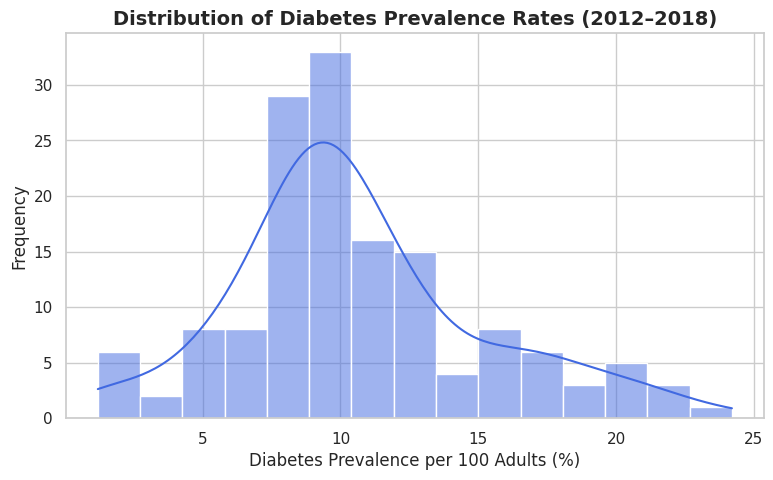

/tmp/ipykernel_964/2119054953.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Strata Name', y=target_col, data=df, palette='Set2')


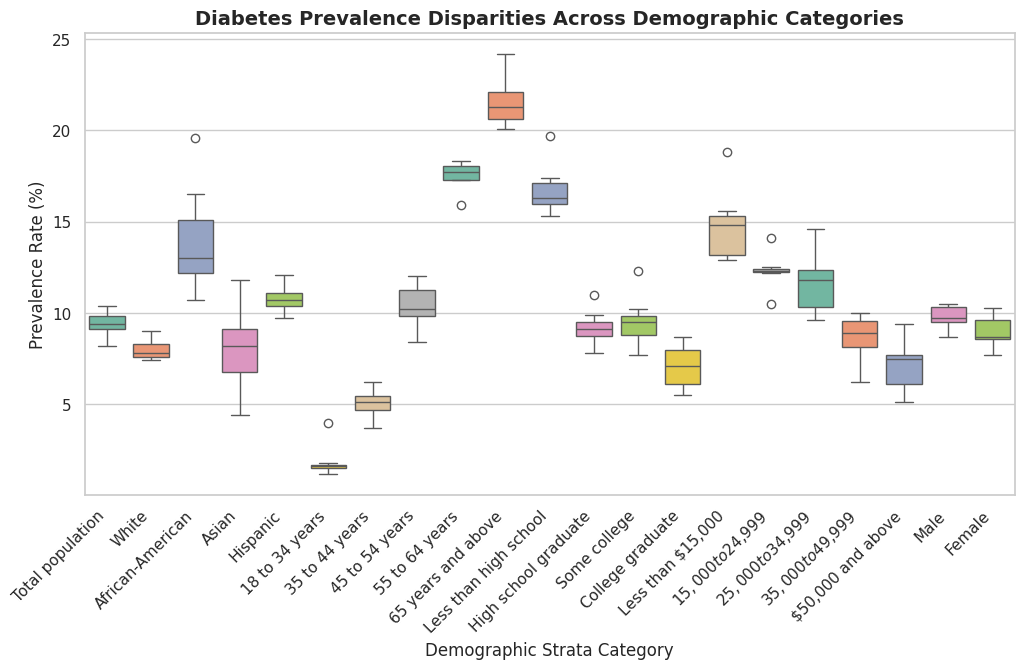

In [13]:
def generate_descriptive_analysis(df, target_col='Percent'):
    """Generates statistical summaries and distribution visualizations."""
    print(f"\n--- Descriptive Statistics for '{target_col}' ---")
    stats = df[target_col].describe()
    variance = df[target_col].var()
    median = df[target_col].median()
    mode = df[target_col].mode().iloc[0]

    print(stats)
    print(f"Variance: {variance:.4f}")
    print(f"Median:   {median:.4f}")
    print(f"Mode:     {mode:.4f}")

    # Visualization 1: Distribution Histogram with KDE
    plt.figure(figsize=(9, 5))
    sns.histplot(df[target_col], kde=True, color='royalblue', bins=15)
    plt.title('Distribution of Diabetes Prevalence Rates (2012–2018)', fontsize=14, fontweight='bold')
    plt.xlabel('Diabetes Prevalence per 100 Adults (%)', fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.savefig('diabetes_distribution_histogram.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Visualization 2: Disparities by Strata Name (Boxplot)
    if 'Strata Name' in df.columns:
        plt.figure(figsize=(12, 6))
        sns.boxplot(x='Strata Name', y=target_col, data=df, palette='Set2')
        plt.xticks(rotation=45, ha='right')
        plt.title('Diabetes Prevalence Disparities Across Demographic Categories', fontsize=14, fontweight='bold')
        plt.xlabel('Demographic Strata Category', fontsize=12)
        plt.ylabel('Prevalence Rate (%)', fontsize=12)
        plt.savefig('disparities_by_strata_boxplot.png', dpi=300, bbox_inches='tight')
        plt.show()

# Run descriptive analysis
generate_descriptive_analysis(df)

In [ ]:
def identify_outliers_and_patterns(df, target_col='Percent'):
    """Identifies statistical outliers using IQR and highlights extreme groups."""
    Q1 = df[target_col].quantile(0.25)
    Q3 = df[target_col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[target_col] < lower_bound) | (df[target_col] > upper_bound)]

    print(f"\n--- Outlier Identification (IQR Method) ---")
    print(f"IQR: {IQR:.4f} | Lower Bound: {lower_bound:.4f} | Upper Bound: {upper_bound:.4f}")
    print(f"Number of statistical outliers detected: {len(outliers)}")
    if len(outliers) > 0:
        print("Outlier records preview:")
        print(outliers[['Year', 'Strata', 'Strata Name', target_col]])
    else:
        print("No extreme mathematical outliers detected beyond standard IQR thresholds, indicating a stable population survey distribution.")

identify_outliers_and_patterns(df)


--- Outlier Identification (IQR Method) ---
IQR: 4.3000 | Lower Bound: 1.5500 | Upper Bound: 18.7500
Number of statistical outliers detected: 13
Outlier records preview:
     Year          Strata            Strata Name  Percent
9    2018             Age     65 years and above     22.4
10   2018       Education  Less than high school     19.7
14   2018          Income      Less than $15,000     18.8
26   2017             Age         18 to 34 years      1.2
30   2017             Age     65 years and above     21.3
47   2016             Age         18 to 34 years      1.5
51   2016             Age     65 years and above     24.2
72   2015             Age     65 years and above     20.5
86   2014  Race-Ethnicity       African-American     19.6
93   2014             Age     65 years and above     21.8
110  2013             Age         18 to 34 years      1.5
114  2013             Age     65 years and above     20.7
135  2012             Age     65 years and above     20.1


In [14]:
def apply_preprocessing_pipeline(df, numerical_features, categorical_features):
    """
    Constructs a ColumnTransformer to handle:
    - StandardScaler: Normalizes numeric columns (e.g., Year) for Ridge regularization balance.
    - OneHotEncoder: Converts categorical strings into binary indicator matrices.
    """
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_features),
            ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features)
        ],
        remainder='drop'
    )

    print("\n--- Executing Justified Transformations ---")
    transformed_matrix = preprocessor.fit_transform(df)

    # Extract feature names for verification
    cat_encoder = preprocessor.named_transformers_['cat']
    encoded_cat_features = list(cat_encoder.get_feature_names_out(categorical_features))
    all_columns = numerical_features + encoded_cat_features

    df_transformed = pd.DataFrame(transformed_matrix, columns=all_columns)
    print(f"Transformation successful! Resulting feature matrix shape: {df_transformed.shape}")
    print("\nPreview of transformed feature matrix:")
    print(df_transformed.head())

    return preprocessor, df_transformed

# Define features based on your dataset columns ['Geography', 'Year', 'Strata', 'Strata Name', 'Percent', ...]
numerical_features = ['Year']
categorical_features = ['Strata', 'Strata Name', 'Geography']

preprocessor, df_transformed = apply_preprocessing_pipeline(df, numerical_features, categorical_features)


--- Executing Justified Transformations ---
Transformation successful! Resulting feature matrix shape: (147, 26)

Preview of transformed feature matrix:
   Year  Strata_Education  Strata_Income  Strata_Race-Ethnicity  Strata_Sex  \
0   1.5               0.0            0.0                    0.0         0.0   
1   1.5               0.0            0.0                    1.0         0.0   
2   1.5               0.0            0.0                    1.0         0.0   
3   1.5               0.0            0.0                    1.0         0.0   
4   1.5               0.0            0.0                    1.0         0.0   

   Strata_Total population  Strata Name_$25,000 to $34,999  \
0                      1.0                             0.0   
1                      0.0                             0.0   
2                      0.0                             0.0   
3                      0.0                             0.0   
4                      0.0                             0.0   

3.2 Model Development and Evaluation

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ------------------------------------------
datafile = "Adults with Diabetes Per 100 (LGHC Indicator 23) (CSV).xlsx"
df = pd.read_excel(datafile, sheet_name='adults-with-diabetes-per-100-lg')

# 1. Define Features and Target
X = df[['Year', 'Strata', 'Strata Name', 'Geography']]
y = df['Percent']

numerical_features = ['Year']
categorical_features = ['Strata', 'Strata Name', 'Geography']

# 2. Setup Preprocessing Pipeline (ColumnTransformer)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features)
    ],
    remainder='drop'
)

# 3. Train/Test Split (80% train, 20% test for initial proof of concept)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
baseline_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

baseline_pipeline.fit(X_train, y_train)
y_pred_base = baseline_pipeline.predict(X_test)

# Calculate metrics
base_mse = mean_squared_error(y_test, y_pred_base)
base_rmse = np.sqrt(base_mse)
base_mae = mean_absolute_error(y_test, y_pred_base)
base_r2 = r2_score(y_test, y_pred_base)

print("--- Baseline Model (OLS Linear Regression) Performance ---")
print(f"MSE:  {base_mse:.4f}")
print(f"RMSE: {base_rmse:.4f}")
print(f"MAE:  {base_mae:.4f}")
print(f"R²:   {base_r2:.4f}")

--- Baseline Model (OLS Linear Regression) Performance ---
MSE:  1.8246
RMSE: 1.3508
MAE:  1.0120
R²:   0.9274


Ridge Regression

In [ ]:
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=1.0))
])

# 5-Fold Cross-Validation Protocol
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(ridge_pipeline, X_train, y_train, cv=kf, scoring='r2')

print("\n--- Ridge Regression Cross-Validation ---")
print(f"5-Fold CV R² Scores: {cv_scores}")
print(f"Mean CV R²: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

# Fit on training data and evaluate on test set
ridge_pipeline.fit(X_train, y_train)
y_pred_ridge = ridge_pipeline.predict(X_test)

ridge_mse = mean_squared_error(y_test, y_pred_ridge)
ridge_rmse = np.sqrt(ridge_mse)
ridge_mae = mean_absolute_error(y_test, y_pred_ridge)
ridge_r2 = r2_score(y_test, y_pred_ridge)

print("\n--- Ridge Regression Test Set Performance ---")
print(f"MSE:  {ridge_mse:.4f}")
print(f"RMSE: {ridge_rmse:.4f}")
print(f"MAE:  {ridge_mae:.4f}")
print(f"R²:   {ridge_r2:.4f}")


--- Ridge Regression Cross-Validation ---
5-Fold CV R² Scores: [0.79941882 0.74027452 0.85081084 0.83303528 0.85101674]
Mean CV R²: 0.8149 (+/- 0.0836)

--- Ridge Regression Test Set Performance ---
MSE:  2.8107
RMSE: 1.6765
MAE:  1.1946
R²:   0.8881


Raw Performance

In [ ]:
metrics_summary = pd.DataFrame({
    'Model': ['Baseline (OLS Linear Regression)', 'Ridge Regression (L2 Penalty)'],
    'MSE': [base_mse, ridge_mse],
    'RMSE': [base_rmse, ridge_rmse],
    'MAE': [base_mae, ridge_mae],
    'R² Score': [base_r2, ridge_r2]
})

print("\n--- Summary Performance Table ---")
print(metrics_summary.to_string(index=False))


--- Summary Performance Table ---
                           Model      MSE     RMSE      MAE  R² Score
Baseline (OLS Linear Regression) 1.824632 1.350789 1.012019  0.927378
   Ridge Regression (L2 Penalty) 2.810651 1.676500 1.194609  0.888133


Visualization

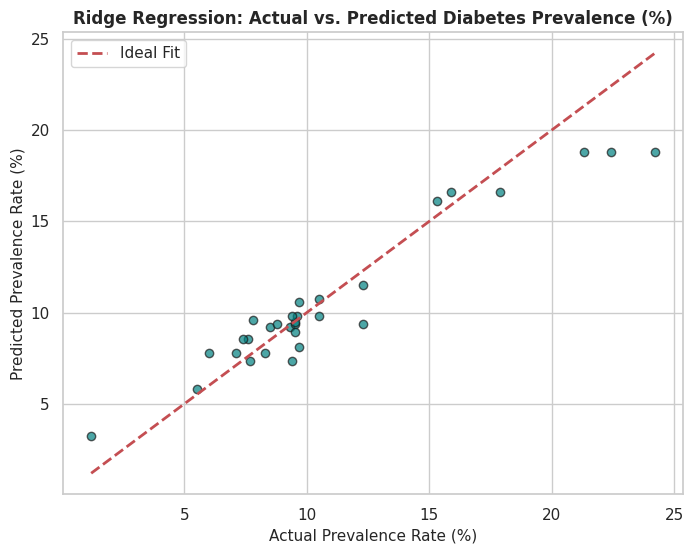

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_ridge, color='teal', alpha=0.7, edgecolors='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Ideal Fit')
plt.title('Ridge Regression: Actual vs. Predicted Diabetes Prevalence (%)', fontsize=12, fontweight='bold')
plt.xlabel('Actual Prevalence Rate (%)', fontsize=11)
plt.ylabel('Predicted Prevalence Rate (%)', fontsize=11)
plt.legend()
plt.savefig('actual_vs_predicted_ridge.png', dpi=300, bbox_inches='tight')
plt.show()

3.3 Validation Protocol

In [15]:
import pandas as pd
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load Data
file_name = 'Adults with Diabetes Per 100 (LGHC Indicator 23) (CSV).xlsx'
df = pd.read_excel(file_name, sheet_name='adults-with-diabetes-per-100-lg')

# Sort chronologically to guarantee strict time order
df = df.sort_values('Year').reset_index(drop=True)

X = df[['Year', 'Strata', 'Strata Name', 'Geography']]
y = df['Percent']

Data-Appropriate Split Strategy

In [16]:
train_mask = df['Year'] <= 2016
test_mask = df['Year'] > 2016

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

print(f"--- Temporal Split Confirmation ---")
print(f"Training Set (Years <= 2016): {X_train.shape[0]} samples")
print(f"Testing Set  (Years > 2016):  {X_test.shape[0]} samples")

--- Temporal Split Confirmation ---
Training Set (Years <= 2016): 105 samples
Testing Set  (Years > 2016):  42 samples


Leakage Prevention Strategy

In [17]:
# Enforcing that StandardScaler and OneHotEncoder are fitted ONLY on X_train
numerical_features = ['Year']
categorical_features = ['Strata', 'Strata Name', 'Geography']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features)
    ],
    remainder='drop'
)

# Encapsulating preprocessing and modeling inside a strict scikit-learn Pipeline
temporal_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=1.0))
])

# Fit strictly on training data (prevents test set feature leakage)
temporal_pipeline.fit(X_train, y_train)

# Predict on unseen chronological test set
y_pred = temporal_pipeline.predict(X_test)

# Evaluate performance
test_mse = mean_squared_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)

print(f"\n--- Temporal Hold-Out Evaluation Metrics ---")
print(f"Test MSE: {test_mse:.4f}")
print(f"Test R²:  {test_r2:.4f}")


--- Temporal Hold-Out Evaluation Metrics ---
Test MSE: 4.1638
Test R²:  0.8131
